# Практична робота 4.8. Регресія та класифікація з використанням TensorFlow

**Номер за журналом: 4** → обсяг даних 1000 × 4 = **4000**, кількість класів 4 + 2 = **6**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.datasets import make_regression, make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

N, K = 1000 * 4, 4 + 2
tf.random.set_seed(42); np.random.seed(42)

## 1. Генерація даних

In [2]:
Xr, yr = make_regression(n_samples=N, n_features=5, noise=15, random_state=42)
Xc, yc = make_classification(n_samples=N, n_features=10, n_informative=6, n_redundant=2,
                             n_classes=K, n_clusters_per_class=1, random_state=42)
print("Регресія:", Xr.shape, " Класифікація:", Xc.shape, " класи:", np.unique(yc))

Регресія: (4000, 5)  Класифікація: (4000, 10)  класи: [0 1 2 3 4 5]


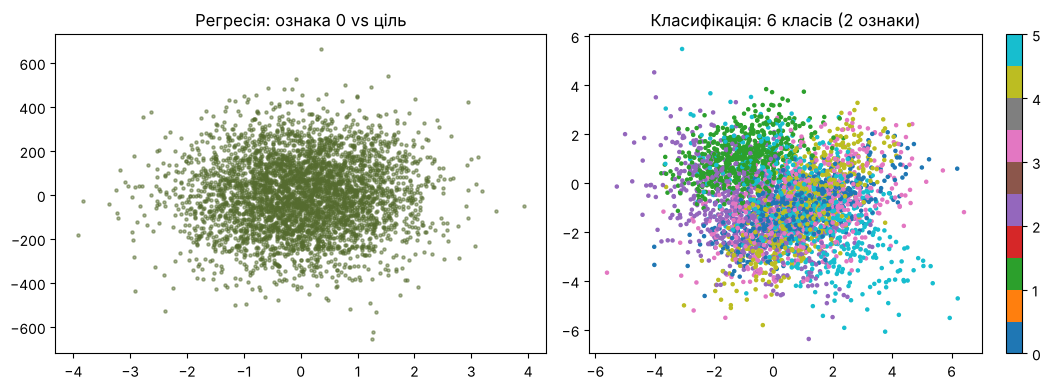

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(Xr[:, 0], yr, s=5, alpha=.5, color="#556b2f"); axes[0].set_title("Регресія: ознака 0 vs ціль")
sc = axes[1].scatter(Xc[:, 0], Xc[:, 1], c=yc, s=5, cmap="tab10"); axes[1].set_title(f"Класифікація: {K} класів (2 ознаки)")
plt.colorbar(sc, ax=axes[1]); plt.tight_layout(); plt.show()

## 2. Регресія: нейронна мережа

In [4]:
Xtr, Xte, ytr, yte = train_test_split(Xr, yr, test_size=0.2, random_state=42)
sx = StandardScaler().fit(Xtr); Xtr, Xte = sx.transform(Xtr), sx.transform(Xte)
reg = keras.Sequential([keras.Input((5,)), keras.layers.Dense(64, activation="relu"),
                        keras.layers.Dense(32, activation="relu"), keras.layers.Dense(1)])
reg.compile(optimizer="adam", loss="mse", metrics=["mae"])
h_reg = reg.fit(Xtr, ytr, validation_split=0.2, epochs=60, batch_size=32, verbose=0)
pr = reg.predict(Xte, verbose=0).ravel()
print(f"MSE = {mean_squared_error(yte, pr):.1f}   R² = {r2_score(yte, pr):.3f}")

MSE = 247.1   R² = 0.991


## 3. Класифікація: нейронна мережа (softmax, 6 класів)

In [5]:
Xtr2, Xte2, ytr2, yte2 = train_test_split(Xc, yc, test_size=0.2, stratify=yc, random_state=42)
sc2 = StandardScaler().fit(Xtr2); Xtr2, Xte2 = sc2.transform(Xtr2), sc2.transform(Xte2)
clf = keras.Sequential([keras.Input((10,)), keras.layers.Dense(64, activation="relu"), keras.layers.Dropout(0.2),
                        keras.layers.Dense(32, activation="relu"), keras.layers.Dense(K, activation="softmax")])
clf.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h_clf = clf.fit(Xtr2, ytr2, validation_split=0.2, epochs=60, batch_size=32, verbose=0)
pc = clf.predict(Xte2, verbose=0).argmax(axis=1)
print(f"Accuracy = {accuracy_score(yte2, pc):.3f}")
print(classification_report(yte2, pc))

Accuracy = 0.889
              precision    recall  f1-score   support

           0       0.86      0.93      0.89       133
           1       0.94      0.95      0.95       133
           2       0.84      0.86      0.85       134
           3       0.96      0.87      0.91       133
           4       0.94      0.89      0.91       133
           5       0.82      0.83      0.82       134

    accuracy                           0.89       800
   macro avg       0.89      0.89      0.89       800
weighted avg       0.89      0.89      0.89       800



## 4. Візуалізація результатів

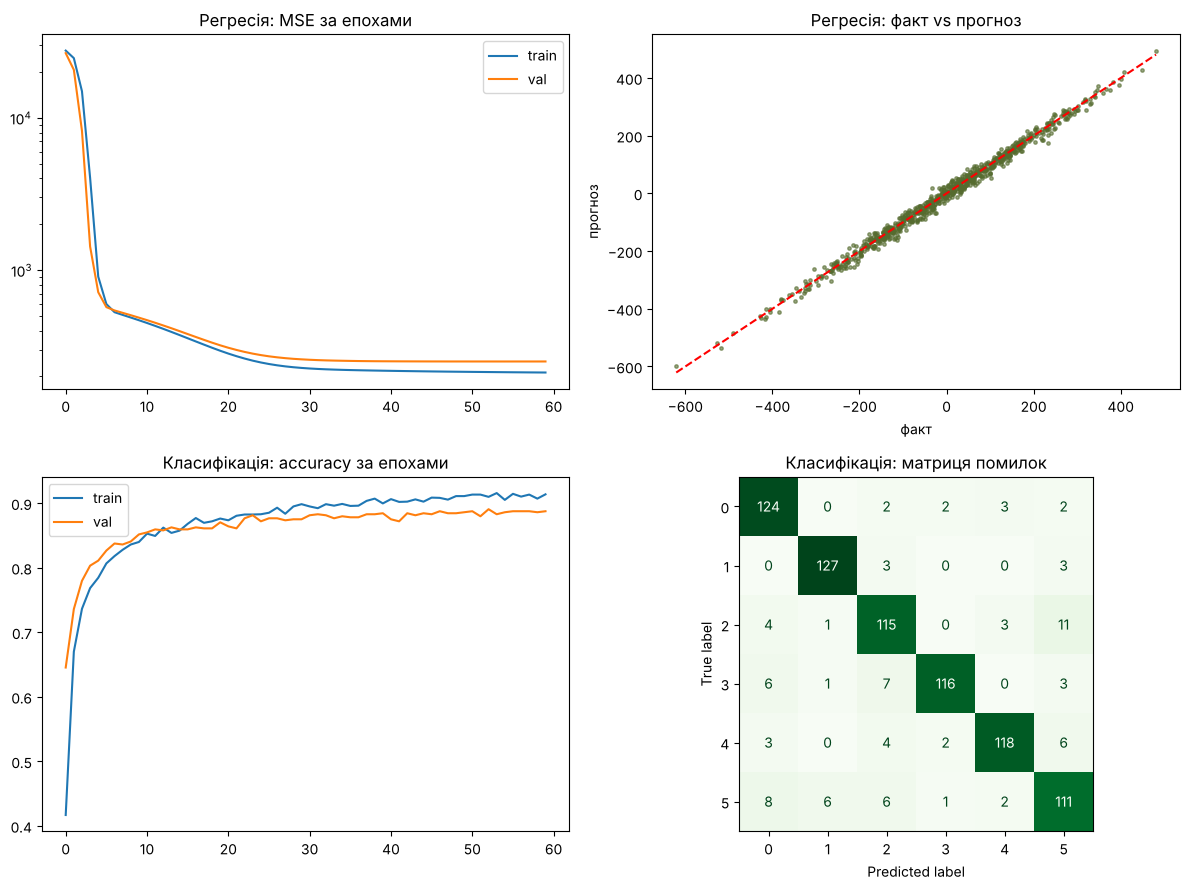

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
ax[0, 0].plot(h_reg.history["loss"], label="train"); ax[0, 0].plot(h_reg.history["val_loss"], label="val")
ax[0, 0].set_title("Регресія: MSE за епохами"); ax[0, 0].set_yscale("log"); ax[0, 0].legend()
ax[0, 1].scatter(yte, pr, s=6, alpha=.6, color="#556b2f"); ax[0, 1].plot([yte.min(), yte.max()], [yte.min(), yte.max()], "r--")
ax[0, 1].set_title("Регресія: факт vs прогноз"); ax[0, 1].set_xlabel("факт"); ax[0, 1].set_ylabel("прогноз")
ax[1, 0].plot(h_clf.history["accuracy"], label="train"); ax[1, 0].plot(h_clf.history["val_accuracy"], label="val")
ax[1, 0].set_title("Класифікація: accuracy за епохами"); ax[1, 0].legend()
ConfusionMatrixDisplay(confusion_matrix(yte2, pc)).plot(ax=ax[1, 1], cmap="Greens", colorbar=False)
ax[1, 1].set_title("Класифікація: матриця помилок")
plt.tight_layout(); plt.show()

## Висновки
1. Регресійна мережа (64-32-1, ReLU, MSE) майже ідеально відтворює лінійну залежність з шумом: R² близький до 1, точки лежать уздовж діагоналі.
2. Класифікаційна мережа (64-32-6, softmax) розрізняє 6 класів з точністю приблизно 0.85–0.9; помилки зосереджені між класами, кластери яких перетинаються.
3. Криві навчання train/val йдуть близько — суттєвого перенавчання немає (допомагає Dropout).
4. Покращити класифікацію можна збільшенням кількості епох, підбором архітектури та ранньою зупинкою (EarlyStopping).